In [25]:
import pandas as pd

df = pd.read_csv("data/house_prices.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())
print(df.info())
print(df.describe())
print(df.isna().mean().sort_values(ascending=False))

Shape: (187531, 21)

Columns: ['Index', 'Title', 'Description', 'Amount(in rupees)', 'Price (in rupees)', 'location', 'Carpet Area', 'Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking', 'Society', 'Bathroom', 'Balcony', 'Car Parking', 'Ownership', 'Super Area', 'Dimensions', 'Plot Area']

First 5 rows:
   Index                                              Title  \
0      0  1 BHK Ready to Occupy Flat for sale in Srushti...   
1      1  2 BHK Ready to Occupy Flat for sale in Dosti V...   
2      2  2 BHK Ready to Occupy Flat for sale in Sunrise...   
3      3        1 BHK Ready to Occupy Flat for sale Kasheli   
4      4  2 BHK Ready to Occupy Flat for sale in TenX Ha...   

                                         Description Amount(in rupees)  \
0  Bhiwandi, Thane has an attractive 1 BHK Flat f...           42 Lac    
1  One can find this stunning 2 BHK flat for sale...           98 Lac    
2  Up for immediate sale is a 2 BHK apartment in ...          1.40 Cr    
3

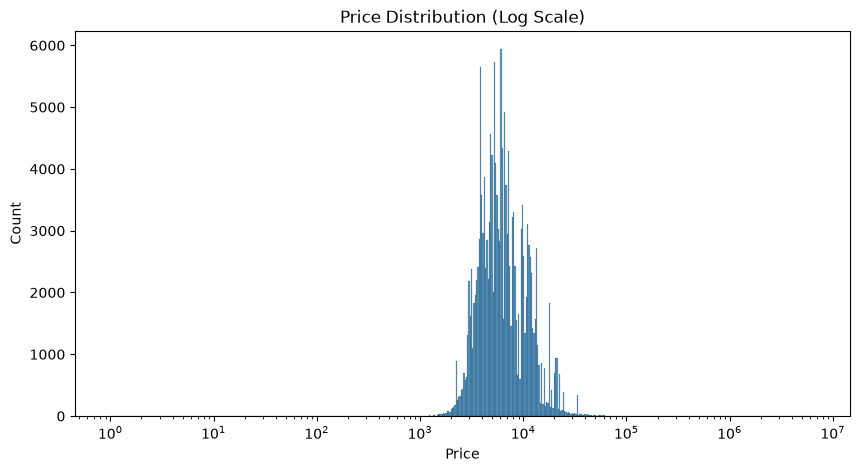

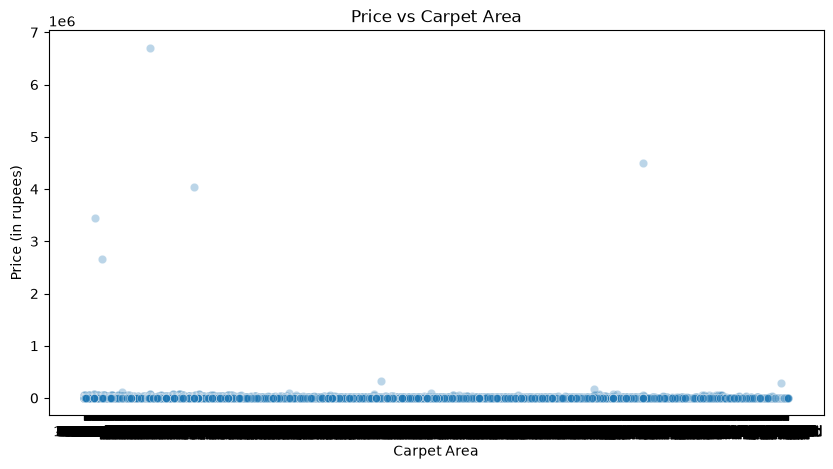

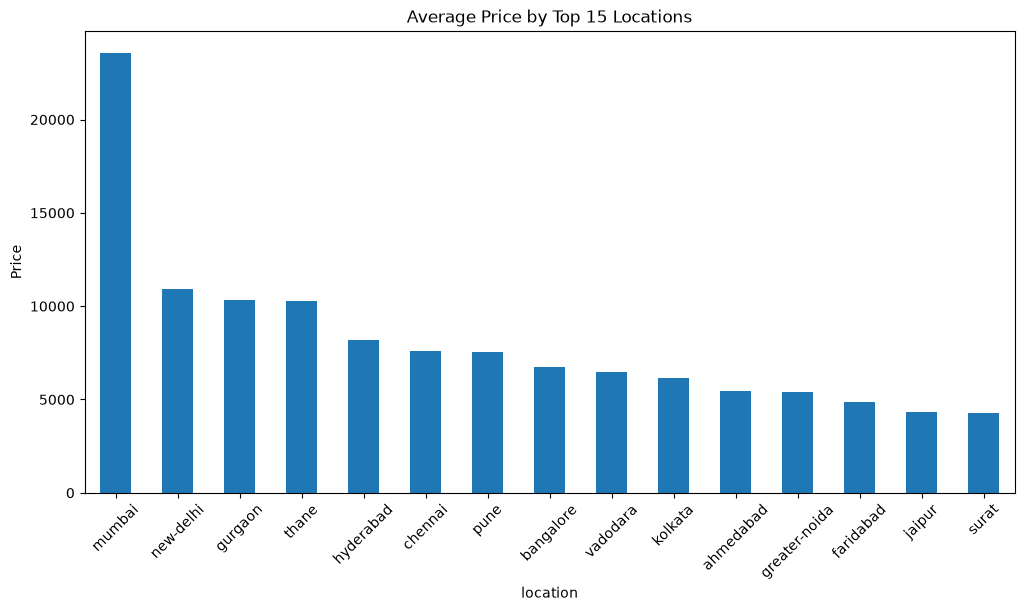

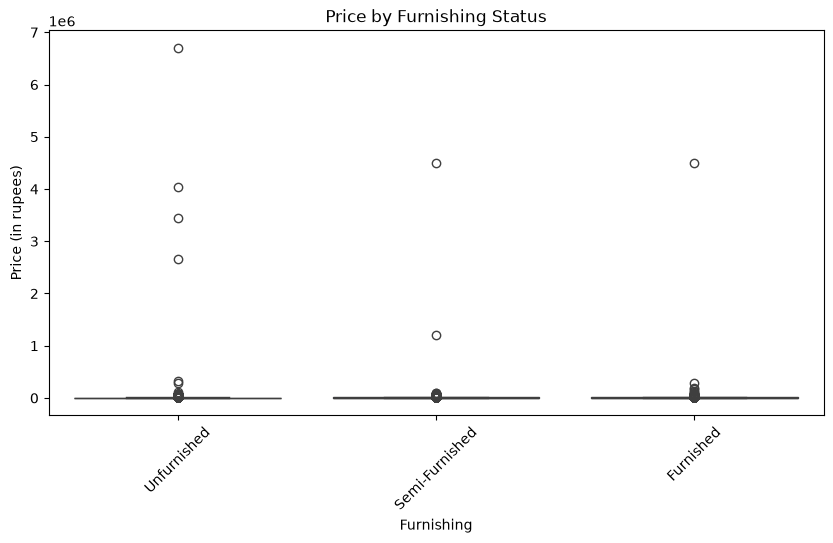

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

#######################################################
plt.figure(figsize=(10, 5))
sns.histplot(df["Price (in rupees)"], log_scale=True)
plt.title("Price Distribution (Log Scale)")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

###############################################################
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Carpet Area", y="Price (in rupees)", alpha=0.3)
plt.title("Price vs Carpet Area")
plt.show()

###############################################################
top15 = df["location"].value_counts().head(15).index
avg_price = df[df["location"].isin(top15)].groupby("location")["Price (in rupees)"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_price.plot(kind="bar")
plt.title("Average Price by Top 15 Locations")
plt.xticks(rotation=45)
plt.ylabel("Price")
plt.show()

###############################################################
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Furnishing", y="Price (in rupees)")
plt.title("Price by Furnishing Status")
plt.xticks(rotation=45)
plt.show()

In [6]:
import numpy as np

def parse_amount(x):
    if not isinstance(x, str):
        return None
    try:
        x = x.replace(" ", "").replace(",", "")
        if "Cr" in x:
            return float(x.replace("Cr", "")) * 10000000
        elif "Lac" in x:
            return float(x.replace("Lac", "")) * 100000
        else:
            return float(x)
    except ValueError:
        return None

df["price_clean"] = df["Amount(in rupees)"].apply(parse_amount)
df = df.dropna(subset=["price_clean"])

print("After price cleaning:", df.shape)

After price cleaning: (177847, 22)


In [7]:
def parse_area(x):
    if not isinstance(x, str):
        return None
    try:
        x = x.replace(" ", "").replace(",", "")
        if "sqm" in x.lower():
            num = float(x.lower().replace("sqm", "").replace("sq.m", ""))
            return num * 10.764
        elif "sqft" in x.lower() or "sq.ft" in x.lower():
            return float(x.lower().replace("sqft", "").replace("sq.ft", ""))
        else:
            return float(x)
    except ValueError:
        return None

df["carpet_area_sqft"] = df["Carpet Area"].apply(parse_area)


In [8]:

def parse_floor(x):
    if not isinstance(x, str):
        return None
    try:
        if "Ground" in x:
            return 0
        elif "Basement" in x:
            return -1
        else:
            return int(x.split("out of")[0].strip())
    except:
        return None

df["floor_num_clean"] = df["Floor"].apply(parse_floor)


In [9]:
df["Bathroom"] = pd.to_numeric(df["Bathroom"], errors="coerce")
df["Balcony"] = pd.to_numeric(df["Balcony"], errors="coerce")
df["Car Parking"] = pd.to_numeric(df["Car Parking"], errors="coerce")

df["Bathroom"] = df["Bathroom"].fillna(0)
df["Balcony"] = df["Balcony"].fillna(0)
df["Car Parking"] = df["Car Parking"].fillna(0)


In [10]:
def location_top(x):
    if x in top50_loc:
        return x
    else:
        return "other"
def society_top(x):
    if x in top50_soc:
        return x
    else:
        return "other"        
top50_loc = df["location"].value_counts().head(50).index
df["location_grouped"] = df["location"].apply(location_top)
top50_soc = df["Society"].value_counts().head(50).index
df["Society_grouped"] = df["Society"].apply(society_top)



In [11]:
# Drop
cols_to_drop = ["Index", "Title", "Description", "Dimensions", 
                "Amount(in rupees)", "Price (in rupees)", "Carpet Area ", 
                "Super Area", "Floor", "location"]
df = df.drop(columns=cols_to_drop, errors="ignore")

#  Outliers
df["pps"] = df["price_clean"] / df["carpet_area_sqft"]
q1 = df["pps"].quantile(0.01)
q99 = df["pps"].quantile(0.99)
df = df[(df["pps"] > q1) & (df["pps"] < q99)]
df = df.drop(columns=["pps"])



In [12]:
print("After cleaning:", df.shape)
print("Columns now:", df.columns.tolist())

After cleaning: (94436, 17)
Columns now: ['Carpet Area', 'Status', 'Transaction', 'Furnishing', 'facing', 'overlooking', 'Society', 'Bathroom', 'Balcony', 'Car Parking', 'Ownership', 'Plot Area', 'price_clean', 'carpet_area_sqft', 'floor_num_clean', 'location_grouped', 'Society_grouped']


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,root_mean_squared_error ,mean_squared_error, r2_score


numeric_features = ["carpet_area_sqft", "floor_num_clean", "Bathroom", "Balcony"]
categorical_features = ["location_grouped", "Furnishing", "Transaction", "Ownership", "facing"]

for col in numeric_features:
    df[col] = df[col].fillna(df[col].median())

 
X = df[numeric_features + categorical_features]
y = df["price_clean"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessor
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
]), categorical_features)])


models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2, "Log": "No"})
    
    pipe_log = Pipeline([("preprocess", preprocess), ("model", model)])
    pipe_log.fit(X_train, np.log1p(y_train))
    pred_log = np.expm1(pipe_log.predict(X_test))
    
    mae_log = mean_absolute_error(y_test, pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, pred))
    r2_log = r2_score(y_test, pred_log)
    results.append({"Model": name + "+Log", "MAE": mae_log, "RMSE": rmse_log, "R2": r2_log, "Log": "Yes"})
    
results_df = pd.DataFrame(results)
print(results_df.sort_values("MAE"))

                  Model           MAE          RMSE            R2  Log
3      RandomForest+Log  9.333814e+05  3.150184e+06  9.422971e-01  Yes
2          RandomForest  9.565031e+05  3.150184e+06  9.442770e-01   No
4      GradientBoosting  2.482154e+06  4.199361e+06  9.009785e-01   No
5  GradientBoosting+Log  2.628860e+06  4.199361e+06  8.695717e-01  Yes
0      LinearRegression  4.157312e+06  6.604975e+06  7.550342e-01   No
1  LinearRegression+Log  4.775177e+08  6.604975e+06 -1.638489e+07  Yes


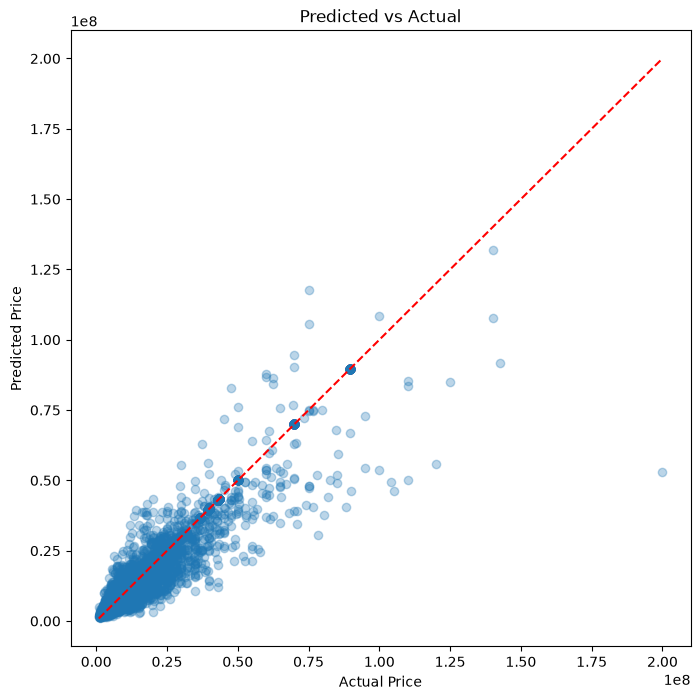


=== Model Comparison ===
                  Model           MAE          RMSE            R2  Log
3      RandomForest+Log  9.333814e+05  3.150184e+06  9.422971e-01  Yes
2          RandomForest  9.565031e+05  3.150184e+06  9.442770e-01   No
4      GradientBoosting  2.482154e+06  4.199361e+06  9.009785e-01   No
5  GradientBoosting+Log  2.628860e+06  4.199361e+06  8.695717e-01  Yes
0      LinearRegression  4.157312e+06  6.604975e+06  7.550342e-01   No
1  LinearRegression+Log  4.775177e+08  6.604975e+06 -1.638489e+07  Yes


In [20]:

best_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])
best_pipe.fit(X_train, np.log1p(y_train))
pred_best = np.expm1(best_pipe.predict(X_test))

# Scatter Plot
plt.figure(figsize=(8, 8))
plt.scatter(y_test, pred_best, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual")
plt.show()

print("\n=== Model Comparison ===")
print(results_df.sort_values("MAE"))

In [22]:
import joblib
import json

best_model = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])
best_model.fit(X_train, np.log1p(y_train))

joblib.dump(best_model, "house_price.pkl")

locations = sorted(df["location_grouped"].unique().tolist())
with open("locations.json", "w") as f:
    json.dump(locations, f)

loaded = joblib.load("house_price.pkl")
sample = X_test.iloc[[0]]
pred = np.expm1(loaded.predict(sample))[0]
print(f"Test prediction: {pred:,.0f}")

Test prediction: 6,512,731
